# Results

Two questions about the Elliptic Bitcoin dataset:

1. Do GCN and GraphSAGE beat LightGBM at finding illicit transactions?
2. How much does a random train/test split inflate the scores compared with a time-based one?

Temporal split: fit on time steps 1-29, validate on 30-34 (early stopping and the decision threshold), test on 35-49. Random split: stratified, same sizes. Every number is the mean of 5 seeds. The scripts `01`-`04` produce everything loaded here.

`local` = 94 features (time step + 93 transaction features), `all` = 166 (adds Elliptic's 72 aggregated neighbour features), `+nbr` = adds the mean of each node's neighbours' local features. `logreg local-no-step` drops the time step; see NOTES.md for why.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
table = pd.read_csv("results/main_table.csv")
runs = pd.concat([pd.read_csv("results/baselines_runs.csv"), pd.read_csv("results/gnn_runs.csv")])
steps = pd.concat([pd.read_csv("results/baselines_per_step.csv"), pd.read_csv("results/gnn_per_step.csv")])
runs["name"] = runs["model"] + " " + runs["features"]
steps["name"] = steps["model"] + " " + steps["features"]
table

,model,temporal_f1_mean,temporal_f1_std,temporal_auprc_mean,temporal_auprc_std,random_f1_mean,random_f1_std,random_auprc_mean,random_auprc_std,f1_gap,auprc_gap
0,logreg local,0.291,0.000,0.173,0.000,0.752,1.340e-02,0.672,0.026,0.461,0.498
1,logreg local-no-step,0.408,0.000,0.196,0.000,0.775,1.450e-02,0.673,0.026,0.367,0.477
2,lgbm local,0.754,0.024,0.782,0.002,0.953,2.900e-03,0.987,0.002,0.199,0.205
3,lgbm all,0.779,0.017,0.792,0.001,0.959,7.100e-03,0.989,0.002,0.180,0.196
4,lgbm local+nbr,0.785,0.015,0.795,0.001,0.957,4.700e-03,0.988,0.002,0.172,0.193
5,lgbm all+nbr,0.793,0.008,0.796,0.001,0.960,7.200e-03,0.989,0.002,0.167,0.193
6,gcn local,0.385,0.069,0.414,0.072,0.773,9.000e-04,0.845,0.008,0.388,0.431
7,gcn all,0.556,0.015,0.503,0.023,0.855,6.600e-03,0.925,0.001,0.299,0.422
8,sage local,0.523,0.019,0.546,0.039,0.882,7.300e-03,0.941,0.005,0.358,0.395
9,sage all,0.629,0.009,0.639,0.014,0.902,3.900e-03,0.952,0.005,0.273,0.313


## Random vs temporal split

Every model scores much higher on the random split. For LightGBM the illicit F1 gap is 0.17-0.20 and AUPRC goes from about 0.79 to 0.99. The GNNs gain more from the random split (0.27-0.39 F1), and logistic regression the most (0.37-0.46).

One reading: under a random split, a test node's neighbours and same-step peers are in the training set, and illicit nodes in the same time step look alike. A GNN that aggregates neighbours benefits directly from that. The temporal split removes it, because no edge crosses a time step.

In [2]:
table[["model", "temporal_f1_mean", "random_f1_mean", "f1_gap", "temporal_auprc_mean", "random_auprc_mean", "auprc_gap"]]

,model,temporal_f1_mean,random_f1_mean,f1_gap,temporal_auprc_mean,random_auprc_mean,auprc_gap
0,logreg local,0.291,0.752,0.461,0.173,0.672,0.498
1,logreg local-no-step,0.408,0.775,0.367,0.196,0.673,0.477
2,lgbm local,0.754,0.953,0.199,0.782,0.987,0.205
3,lgbm all,0.779,0.959,0.180,0.792,0.989,0.196
4,lgbm local+nbr,0.785,0.957,0.172,0.795,0.988,0.193
5,lgbm all+nbr,0.793,0.960,0.167,0.796,0.989,0.193
6,gcn local,0.385,0.773,0.388,0.414,0.845,0.431
7,gcn all,0.556,0.855,0.299,0.503,0.925,0.422
8,sage local,0.523,0.882,0.358,0.546,0.941,0.395
9,sage all,0.629,0.902,0.273,0.639,0.952,0.313


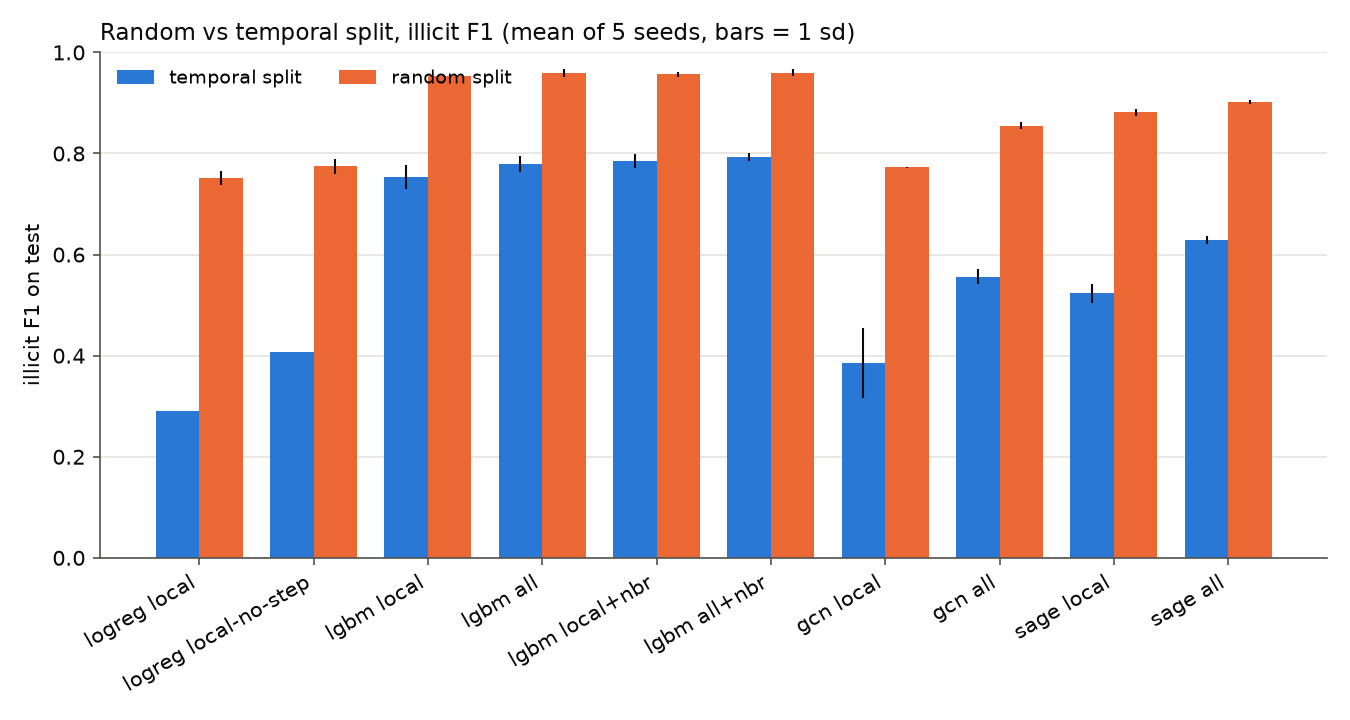

In [3]:
display(Image("figures/random_vs_temporal.png"))

## Do the GNNs beat LightGBM under the temporal split?

No. The best GNN (GraphSAGE on all features) gets 0.629 ± 0.009 illicit F1; the best LightGBM (all features + neighbour means) gets 0.793 ± 0.008. LightGBM on all features beats GraphSAGE on all features on every one of the 5 seeds. AUPRC tells the same story (0.80 vs 0.64).

The cheap graph feature helps LightGBM a little: local 0.754 → local+nbr 0.785, all 0.779 → all+nbr 0.793. That's a smaller gain than the spread between model families.

In [4]:
temporal = runs[runs["split"] == "temporal"]
per_seed = temporal.pivot(index="seed", columns="name", values="f1")
per_seed[["lgbm all", "lgbm all+nbr", "gcn all", "sage all", "sage local"]]

name,lgbm all,lgbm all+nbr,gcn all,sage all,sage local
seed,,,,,
0,0.784,0.790,0.561,0.629,0.515
1,0.751,0.797,0.544,0.639,0.537
2,0.779,0.805,0.563,0.615,0.494
3,0.791,0.788,0.575,0.630,0.533
4,0.792,0.786,0.540,0.629,0.538


In [5]:
# Gap between the best LightGBM and the best GNN, paired by seed.
(per_seed["lgbm all"] - per_seed["sage all"]).describe()[["mean", "std", "min", "max"]]

mean    0.151
std     0.022
min     0.112
max     0.164
dtype: float64

## Illicit F1 per test time step

All models track each other from 35 to 42, with LightGBM highest at every step. At step 43 every model drops to nearly zero F1 and stays there through step 49.

The bottom panel shows the number of illicit labels per step. They fall from 239 at step 42 to 24, 24, 5 and 2 at steps 43-46, then rise again to 22, 36 and 56 at steps 47-49. The table below shows the drop is a recall problem: from step 43 on, the models miss almost all illicit nodes, even at steps 47-49 where there are more to find again.

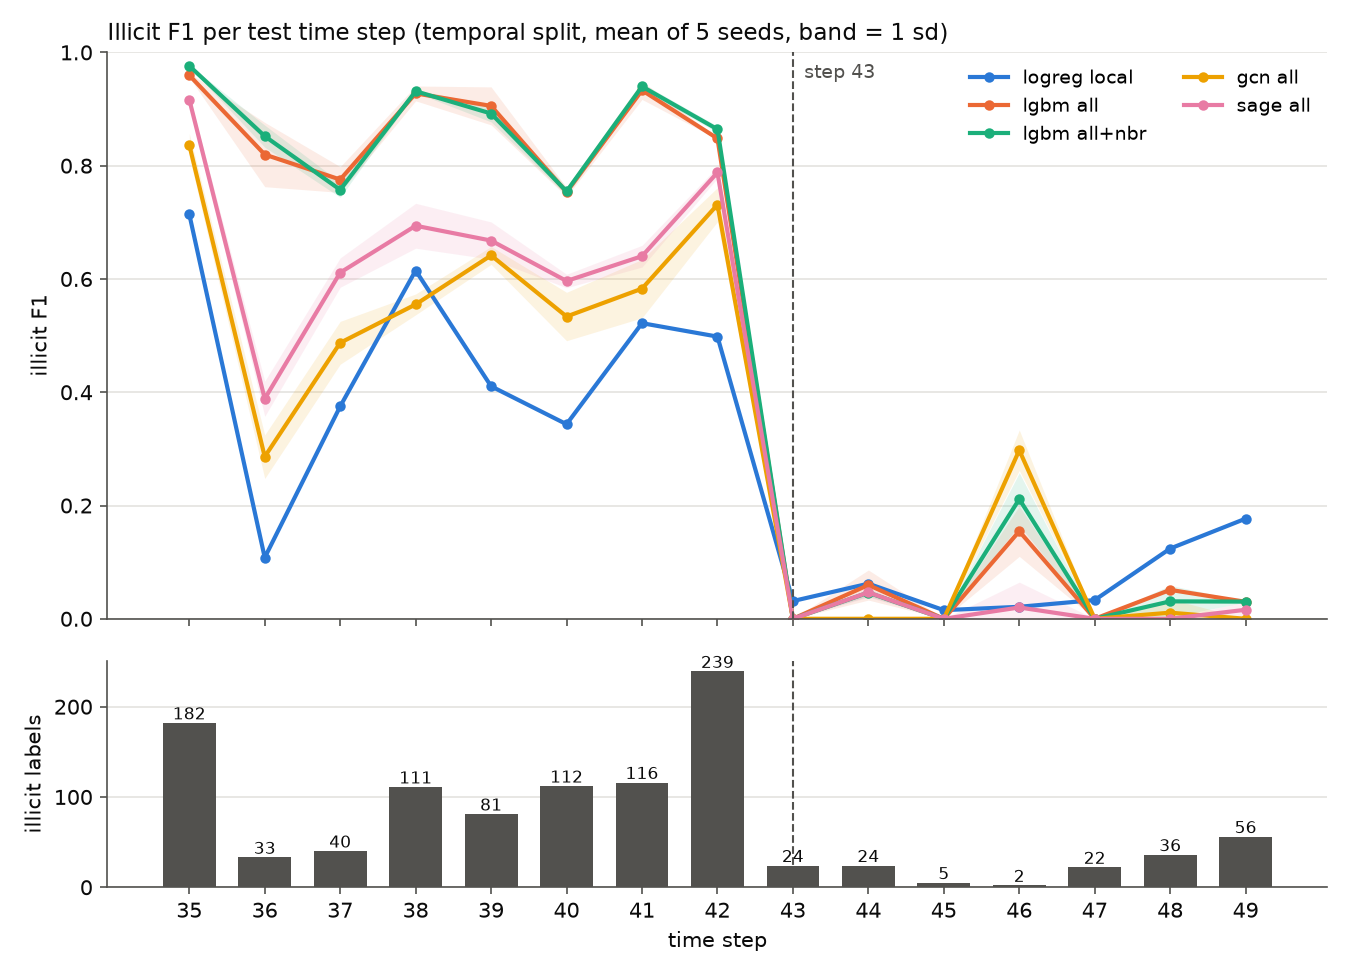

In [6]:
display(Image("figures/f1_per_step.png"))

In [7]:
cols = ["lgbm all", "sage all", "gcn all"]
view = steps[steps["name"].isin(cols)].groupby(["step", "name"])[["recall", "precision"]].mean().unstack("name")
view.insert(0, "n_illicit", steps.groupby("step")["n_illicit"].first())
view.round(2)

C:\Users\MOD\AppData\Local\Temp\ipykernel_21540\966049014.py:3: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  view.insert(0, "n_illicit", steps.groupby("step")["n_illicit"].first())


n_illicit  recall                   precision                  
name           gcn all lgbm all sage all   gcn all lgbm all sage all
step                                                                
35         182    0.82     0.97     0.91      0.86     0.95     0.92
36          33    0.45     0.97     0.73      0.21     0.71     0.26
37          40    0.52     0.64     0.58      0.46     0.98     0.65
38         111    0.67     0.91     0.83      0.47     0.95     0.60
39          81    0.70     0.92     0.65      0.59     0.89     0.69
40         112    0.41     0.68     0.49      0.77     0.85     0.76
41         116    0.50     0.95     0.65      0.70     0.92     0.63
42         239    0.63     0.80     0.75      0.87     0.90     0.83
43          24    0.00     0.00     0.00      0.00     0.00     0.00
44          24    0.00     0.07     0.04      0.00     0.06     0.06
45           5    0.00     0.00     0.00      0.00     0.00     0.00
46           2    0.50     0.50     0.10      0.21     0.09     0.01
47          22    0.00     0.00     0.00      0.00     0.00     0.00
48          36    0.01     0.03     0.00      0.50     0.33     0.00
49          56    0.00     0.02     0.01      0.00     0.10     0.03

## What changes after step 43

Weber et al. link the late drop to a dark market shutdown. I wanted to see what the data itself shows, without assuming that.

First try (dead end, details in NOTES.md): a classifier that tells early from late nodes within one class reaches AUC 1.0 for licit nodes as well as illicit ones, so some features track time and that check can't isolate illicit drift.

The check below is more direct. For each test node, look at its 10 nearest labelled training nodes (steps 1-34) in local-feature space, without the time step, and count how many are illicit.

In [8]:
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

d = np.load("data/processed/elliptic.npz")
x, y, t = d["x"][:, 1:94], d["y"], d["t"]  # local features without the time step
train = np.where((y >= 0) & (t <= 34))[0]
scaler = StandardScaler().fit(x[train])
nn = NearestNeighbors(n_neighbors=10).fit(scaler.transform(x[train]))

rows = []
for cls, label in [(1, "illicit"), (0, "licit")]:
    for lo, hi in [(35, 42), (43, 49)]:
        q = np.where((y == cls) & (t >= lo) & (t <= hi))[0]
        _, idx = nn.kneighbors(scaler.transform(x[q]))
        share = (y[train][idx] == 1).mean(1)
        rows.append({"class": label, "steps": f"{lo}-{hi}", "n": len(q),
                     "illicit share of 10 nearest train nodes": share.mean(),
                     "share with mostly illicit neighbours": (share > 0.5).mean()})
pd.DataFrame(rows)

,class,steps,n,illicit share of 10 nearest train nodes,share with mostly illicit neighbours
0,illicit,35-42,914,0.786,0.817
1,illicit,43-49,169,0.067,0.006
2,licit,35-42,9069,0.052,0.020
3,licit,43-49,6518,0.056,0.015


In steps 35-42, illicit nodes sit among training illicit nodes (about 79% of their nearest neighbours are illicit). From step 43 on, illicit nodes sit among licit ones (about 7%), no differently from licit nodes (5-6%). So after step 43, the illicit transactions in the test data don't resemble the illicit transactions the models learned from, and no model here can find them from past patterns. That fits a change in who is behind the illicit activity, such as a market closing, but the dataset is anonymised and can't confirm the cause.

## Summary

- Under the temporal split, LightGBM beats both GNNs by about 0.16 illicit F1 (0.79 vs 0.63 at best), on every seed.
- The random split inflates illicit F1 by 0.17-0.20 for LightGBM and by 0.27-0.39 for the GNNs, so it narrows the apparent gap between the two.
- Every model fails from step 43 on, because the illicit nodes there look like licit ones by every pattern in the training period.